# Human-in-the-Loop Content Refresh Opportunity Scoring

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kifayat-Sayed/kifayat-flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb)

**Machine Learning Capstone — Week 8**

This project develops a content review prioritization workflow using anonymized search and content-performance data.

The objective is to identify content items that may deserve human review using historical content attributes and search-performance signals.

The model is evaluated against a simple business-rule baseline, with a client-grouped holdout to assess generalization to unseen clients.

The output is a ranked review queue, not an automatic content-refresh decision.

## 1. Question

## 1. Research Question

Can historical content and search-performance signals help prioritize pages for content review, and does a machine-learning ranking approach generalize to clients not seen during training?

### Decision supported

The project supports editorial teams in prioritizing which content items to inspect first when review resources are limited.

The system is designed for human decision support. It does not establish that a page will decline in the future or that refreshing it will improve search performance.

In [21]:
from pathlib import Path
import subprocess
import warnings
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42

REPO_URL = (
    "https://github.com/"
    "Kifayat-Sayed/flyrank-ml-internship1.git"
)

REPO_DIR = Path("/content/Kifayat-Sayed/flyrank-ml-internship1")

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)],
        check=True
    )

DATA_PATH = REPO_DIR / "data/raw/content_refresh_anonymized.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}"
    )

data = pd.read_csv(DATA_PATH)

required = {
    "content_id",
    "client_id",
    "trend_direction",
    "trend_pct",
    "days_since_last_update",
    "impressions_90d"
}

missing = required - set(data.columns)

if missing:
    raise ValueError(
        f"Missing required columns: {sorted(missing)}"
    )

data["is_declining_label"] = (
    data["trend_direction"]
    .astype(str)
    .str.lower()
    .eq("down")
    .astype(int)
)

print("DATASET LOADED SUCCESSFULLY")
print("-" * 40)
print("Rows:", f"{len(data):,}")
print("Columns:", len(data.columns))
print("Unique clients:", data["client_id"].nunique())
print(
    "Observed decline-label prevalence:",
    f"{data['is_declining_label'].mean():.1%}"
)
print("Dataset path:", DATA_PATH)

DATASET LOADED SUCCESSFULLY
----------------------------------------
Rows: 30,000
Columns: 45
Unique clients: 32
Observed decline-label prevalence: 54.2%
Dataset path: /content/Kifayat-Sayed/flyrank-ml-internship1/data/raw/content_refresh_anonymized.csv


In [22]:
print("DATASET OVERVIEW")
display(data.head())

print("\nDATA TYPES")
display(data.dtypes.to_frame("dtype"))

print("\nMISSING VALUES (%)")
display(
    (data.isna().mean() * 100)
    .sort_values(ascending=False)
    .head(20)
    .to_frame("missing_percentage")
)

print("\nLABEL DISTRIBUTION")
display(
    data["is_declining_label"]
    .value_counts()
    .rename(index={0: "Not labelled down", 1: "Labelled down"})
    .to_frame("records")
)

print("\nDUPLICATE CONTENT IDS:", data["content_id"].duplicated().sum())
print("CLIENT COUNT:", data["client_id"].nunique())

DATASET OVERVIEW


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct,is_declining_label
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4,1
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7,1
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9,1
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,0.49,6.2,1.28,3.45,0.0,good,page_1,stable,-13.8,0
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,0.13,44.0,0.00,24.29,0.0,good,page_3_5,down,-34.7,1



DATA TYPES


,dtype
content_id,object
client_id,object
search_volume,float64
competition,float64
competition_level,object
cpc,float64
content_type,object
main_intent,object
word_count,float64
char_count,float64



MISSING VALUES (%)


,missing_percentage
provider_used,71.460000
word_count,25.663333
char_count,25.663333
char_count_tier,25.663333
word_count_tier,25.663333
model_used,19.110000
trend_pct,11.293333
competition_level,8.700000
cpc,8.226667
search_volume,8.226667



LABEL DISTRIBUTION


,records
is_declining_label,
Labelled down,16262
Not labelled down,13738



DUPLICATE CONTENT IDS: 0
CLIENT COUNT: 32


In [23]:
TARGET = "is_declining_label"

EXCLUDED = {
    "content_id",
    "client_id",
    TARGET,
    "trend_direction",
    "trend_pct",
    "impressions_last_30d",
    "impressions_prev_30d",
    "clicks_last_30d",
    "clicks_prev_30d",
    "sessions_last_30d",
    "sessions_prev_30d",
    "provider_used",
    "model_used"
}

feature_cols = [
    col for col in data.columns
    if col not in EXCLUDED and not data[col].isna().all()
]

X = data[feature_cols].copy()
y = data[TARGET].astype(int)
groups = data["client_id"]

numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

print("Total features:", len(feature_cols))
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Excluded leakage-sensitive fields:", sorted(EXCLUDED))

Total features: 32
Numeric features: 23
Categorical features: 9
Excluded leakage-sensitive fields: ['clicks_last_30d', 'clicks_prev_30d', 'client_id', 'content_id', 'impressions_last_30d', 'impressions_prev_30d', 'is_declining_label', 'model_used', 'provider_used', 'sessions_last_30d', 'sessions_prev_30d', 'trend_direction', 'trend_pct']



## 2. Data and Data Quality

The project uses the anonymized content-refresh dataset supplied for the FlyRank ML internship.

The extract contains one row per content item and includes content attributes, search-performance indicators, and trend information.

The analysis uses the supplied trailing 90-day metrics and recent 30-day comparisons. The exact calendar date range is not established by the available dataset documentation, so no specific dates are assumed.

### Target definition

The binary target is derived from `trend_direction`:

- `1`: trend direction is down.
- `0`: trend direction is not down.

The target is an observed label derived from `trend_pct`, not an independently verified future outcome.

### Data exclusions

Identifiers, target-generating fields, direct label ingredients, and provider/model metadata are excluded from model features.

The client identifier is used only to keep clients separated during grouped validation.

In [24]:
# Data quality checks

print("DATA QUALITY SUMMARY")
print("=" * 50)

print("Total records:", f"{len(data):,}")
print("Unique content IDs:", data["content_id"].nunique())
print("Unique clients:", data["client_id"].nunique())

print(
    "Duplicate content IDs:",
    data["content_id"].duplicated().sum()
)

print("\nTarget distribution:")
display(
    data["is_declining_label"]
    .value_counts()
    .rename(index={
        0: "Not labelled down",
        1: "Labelled down"
    })
    .to_frame("Number of records")
)

print("\nMissing values in the most affected fields:")
display(
    (data.isna().mean() * 100)
    .sort_values(ascending=False)
    .head(15)
    .round(2)
    .to_frame("Missing percentage")
)

DATA QUALITY SUMMARY
Total records: 30,000
Unique content IDs: 30000
Unique clients: 32
Duplicate content IDs: 0

Target distribution:


,Number of records
is_declining_label,
Labelled down,16262
Not labelled down,13738



Missing values in the most affected fields:


,Missing percentage
provider_used,71.46
word_count,25.66
char_count,25.66
char_count_tier,25.66
word_count_tier,25.66
model_used,19.11
trend_pct,11.29
competition_level,8.70
cpc,8.23
search_volume,8.23


## 3. Methodology

### Target and feature selection

The prediction target is `is_declining_label`, derived from the supplied trend direction.

Features include available content attributes and historical performance indicators, excluding direct target ingredients and identifiers.

### Preprocessing

- Numerical features: median imputation with missingness indicators.
- Categorical features: most-frequent imputation followed by one-hot encoding.
- Unseen categories: handled using `handle_unknown="ignore"`.

All preprocessing is fitted inside the training pipeline to avoid fitting transformations on the test set.

### Machine-learning model

A Random Forest classifier is used with:

- 120 decision trees
- Minimum samples per leaf: 5
- Class weighting: balanced subsample
- Random seed: 42

### Baseline

The Week 4 baseline ranks pages using a simple rule:

- Last updated at least 180 days ago.
- At least 3,000 impressions over 90 days.
- Eligible pages are ranked by their 90-day impressions.

### Validation strategy

Two evaluations are used:

1. Random-row split: diagnostic comparison only.
2. Client-grouped holdout: primary evaluation, with no client appearing in both training and test partitions.

### Evaluation metrics

Precision@20 and Precision@50 measure the proportion of labelled-down pages among the top 20 and top 50 ranked items.

The model and baseline are evaluated on exactly the same test records.

In [25]:
# Build the preprocessing and machine-learning pipeline

def make_model():

    numeric_pipe = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        )
    ])

    categorical_pipe = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=10
            )
        )
    ])

    preprocessing = ColumnTransformer([
        ("numeric", numeric_pipe, numeric_features),
        ("categorical", categorical_pipe, categorical_features)
    ])

    model = Pipeline([
        ("preprocess", preprocessing),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=120,
                min_samples_leaf=5,
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=SEED
            )
        )
    ])

    return model


# Precision at K evaluation function

def precision_at_k(y_true, scores, k):

    y_true = np.asarray(y_true)
    scores = np.asarray(scores)

    top_indices = np.argsort(
        -scores,
        kind="stable"
    )[:min(k, len(y_true))]

    return float(y_true[top_indices].mean())


# Week 4 business-rule baseline

def baseline_score(frame):

    age = pd.to_numeric(
        frame["days_since_last_update"],
        errors="coerce"
    )

    impressions = pd.to_numeric(
        frame["impressions_90d"],
        errors="coerce"
    ).fillna(0)

    eligible = (
        age.ge(180).fillna(False)
        & impressions.ge(3000)
    )

    return eligible.astype(int) * impressions


print("Model pipeline created.")
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(feature_cols))

Model pipeline created.
Numeric features: 23
Categorical features: 9
Total features: 32


## 4. Results: Machine Learning Model vs Baseline

The main evaluation compares the Random Forest model against the Week 4 rule-based baseline.

Both approaches are evaluated on the same client-grouped test set.

The random-row split is shown as a diagnostic only. The client-grouped holdout is the primary result because it evaluates performance on clients excluded from model training.

The comparison focuses on Precision@20 and Precision@50. A higher score means a greater proportion of the top-ranked items match the observed decline label.

In [26]:
# 1. Random-row diagnostic split

row_train_idx, row_test_idx = train_test_split(
    np.arange(len(data)),
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

row_model = make_model()

row_model.fit(
    X.iloc[row_train_idx],
    y.iloc[row_train_idx]
)

row_scores = row_model.predict_proba(
    X.iloc[row_test_idx]
)[:, 1]

row_y = y.iloc[row_test_idx]

row_baseline = baseline_score(
    data.iloc[row_test_idx]
)


# 2. Client-grouped primary evaluation

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

group_train_idx, group_test_idx = next(
    gss.split(X, y, groups=groups)
)

train_clients = set(
    groups.iloc[group_train_idx]
)

test_clients = set(
    groups.iloc[group_test_idx]
)

assert train_clients.isdisjoint(test_clients), (
    "ERROR: Client overlap detected."
)

group_model = make_model()

group_model.fit(
    X.iloc[group_train_idx],
    y.iloc[group_train_idx]
)

group_scores = group_model.predict_proba(
    X.iloc[group_test_idx]
)[:, 1]

group_y = y.iloc[group_test_idx]

group_test_data = data.iloc[group_test_idx].copy()

group_baseline = baseline_score(
    group_test_data
)


# 3. Calculate Precision@20 and Precision@50

results = []

evaluation_sets = [
    (
        "Random-row diagnostic",
        row_y,
        row_scores,
        row_baseline
    ),
    (
        "Client-grouped primary",
        group_y,
        group_scores,
        group_baseline
    )
]

for split_name, actual, model_scores, baseline_scores in evaluation_sets:

    results.append({
        "Split": split_name,
        "Method": "Week-4 rule baseline",
        "Precision@20": precision_at_k(
            actual, baseline_scores, 20
        ),
        "Precision@50": precision_at_k(
            actual, baseline_scores, 50
        )
    })

    results.append({
        "Split": split_name,
        "Method": "Random Forest",
        "Precision@20": precision_at_k(
            actual, model_scores, 20
        ),
        "Precision@50": precision_at_k(
            actual, model_scores, 50
        )
    })


comparison = pd.DataFrame(results)

print("MODEL EVALUATION RESULTS")
display(
    comparison.style.format({
        "Precision@20": "{:.1%}",
        "Precision@50": "{:.1%}"
    })
)

print("\nCLIENT-GROUPED VALIDATION")
print("Training records:", len(group_train_idx))
print("Testing records:", len(group_test_idx))
print("Training clients:", len(train_clients))
print("Testing clients:", len(test_clients))
print("Client overlap:", len(train_clients & test_clients))

assert len(train_clients & test_clients) == 0

MODEL EVALUATION RESULTS


,Split,Method,Precision@20,Precision@50
0,Random-row diagnostic,Week-4 rule baseline,60.0%,64.0%
1,Random-row diagnostic,Random Forest,100.0%,98.0%
2,Client-grouped primary,Week-4 rule baseline,80.0%,70.0%
3,Client-grouped primary,Random Forest,65.0%,62.0%



CLIENT-GROUPED VALIDATION
Training records: 23837
Testing records: 6163
Training clients: 25
Testing clients: 7
Client overlap: 0


## 5. Limitations and Honest Interpretation

This project has several important limitations.

1. **Observed label:** The target is derived from the supplied trend information. It is not a verified future decline outcome.
2. **Single snapshot:** The available extract does not establish a precise calendar date range or prove that every feature was measured before the label.
3. **Client generalization:** The grouped holdout tests performance on held-out clients within this dataset. It does not guarantee performance on all future clients.
4. **Baseline comparison:** A simple rule-based baseline may outperform the Random Forest. This result must be reported honestly.
5. **No causal evidence:** The analysis does not demonstrate that refreshing content causes better search performance.
6. **Human review required:** Predictions and ranking scores are prioritization signals, not automatic editorial decisions.
7. **Reason-code limitations:** The reason codes used in the recommendation queue are transparent heuristics, not SHAP explanations.

The system should therefore be interpreted as an experimental decision-support workflow.

In [27]:
# Detailed grouped holdout evaluation

group_predictions = (
    group_scores >= 0.50
).astype(int)

print("GROUPED HOLDOUT CLASSIFICATION REPORT")
print(
    classification_report(
        group_y,
        group_predictions,
        target_names=[
            "Not labelled down",
            "Labelled down"
        ],
        zero_division=0
    )
)

print("CONFUSION MATRIX")
print(
    confusion_matrix(
        group_y,
        group_predictions
    )
)

print("\nBASELINE COMPARISON")

primary_results = comparison[
    comparison["Split"] == "Client-grouped primary"
].copy()

display(
    primary_results.style.format({
        "Precision@20": "{:.1%}",
        "Precision@50": "{:.1%}"
    })
)

for metric in ["Precision@20", "Precision@50"]:

    model_value = primary_results.loc[
        primary_results["Method"] == "Random Forest",
        metric
    ].iloc[0]

    baseline_value = primary_results.loc[
        primary_results["Method"] == "Week-4 rule baseline",
        metric
    ].iloc[0]

    difference = model_value - baseline_value

    print(
        f"{metric}: model minus baseline = "
        f"{difference:+.1%}"
    )

GROUPED HOLDOUT CLASSIFICATION REPORT
                   precision    recall  f1-score   support

Not labelled down       0.58      0.57      0.58      3014
    Labelled down       0.60      0.61      0.60      3149

         accuracy                           0.59      6163
        macro avg       0.59      0.59      0.59      6163
     weighted avg       0.59      0.59      0.59      6163

CONFUSION MATRIX
[[1724 1290]
 [1239 1910]]

BASELINE COMPARISON


,Split,Method,Precision@20,Precision@50
2,Client-grouped primary,Week-4 rule baseline,80.0%,70.0%
3,Client-grouped primary,Random Forest,65.0%,62.0%


Precision@20: model minus baseline = -15.0%
Precision@50: model minus baseline = -8.0%


## 6. Ranked Recommendations and Action Playbook

The model produces a ranked list of content items that can be reviewed by an editorial team.

The queue is intended to help teams allocate review time. It does not automatically recommend that every high-scoring item should be refreshed.

### Review priorities

- High model score: inspect the page and validate whether a refresh opportunity exists.
- Stale, high-impression content: check whether the page remains accurate and useful.
- Search-position opportunity: inspect content ranking in the context of its search intent.
- Low engagement: investigate whether the title, description, or content matches user expectations.

All recommendations require human review before action.

In [28]:
# Create a ranked review queue from the grouped holdout

review_queue = group_test_data.copy()

review_queue["model_review_score"] = group_scores

review_queue["baseline_score"] = (
    group_baseline.to_numpy()
)


def assign_reason_codes(row):

    reasons = []

    age = pd.to_numeric(
        pd.Series([row.get("days_since_last_update")]),
        errors="coerce"
    ).iloc[0]

    impressions = pd.to_numeric(
        pd.Series([row.get("impressions_90d")]),
        errors="coerce"
    ).iloc[0]

    position = pd.to_numeric(
        pd.Series([row.get("avg_position")]),
        errors="coerce"
    ).iloc[0]

    ctr = pd.to_numeric(
        pd.Series([row.get("ctr")]),
        errors="coerce"
    ).iloc[0]

    if (
        pd.notna(age)
        and age >= 180
        and pd.notna(impressions)
        and impressions >= 3000
    ):
        reasons.append("STALE_HIGH_VALUE")

    if (
        pd.notna(position)
        and 4 <= position <= 20
        and pd.notna(impressions)
        and impressions >= 300
    ):
        reasons.append("POSITION_OPPORTUNITY")

    if (
        pd.notna(ctr)
        and ctr <= 0.5
        and pd.notna(impressions)
        and impressions >= 300
    ):
        reasons.append("LOW_ENGAGEMENT")

    if not reasons:
        reasons.append("MODEL_REVIEW_FLAG")

    return " | ".join(reasons)


review_queue["review_reason_code"] = (
    review_queue.apply(assign_reason_codes, axis=1)
)

review_queue = review_queue.sort_values(
    "model_review_score",
    ascending=False
).reset_index(drop=True)

review_queue.insert(
    0,
    "review_priority",
    np.arange(1, len(review_queue) + 1)
)

display_columns = [
    col for col in [
        "review_priority",
        "model_review_score",
        "review_reason_code",
        "content_id",
        "client_id",
        "content_type",
        "days_since_last_update",
        "impressions_90d",
        "avg_position",
        "ctr"
    ]
    if col in review_queue.columns
]

print("TOP 20 CONTENT ITEMS FOR INTERNAL REVIEW")

display(
    review_queue[display_columns].head(20)
)

print(
    "\nNote: This queue is for internal analysis. "
    "Do not publish content IDs, client IDs, or individual rows."
)

TOP 20 CONTENT ITEMS FOR INTERNAL REVIEW


,review_priority,model_review_score,review_reason_code,content_id,client_id,content_type,days_since_last_update,impressions_90d,avg_position,ctr
0,1,0.942095,POSITION_OPPORTUNITY | LOW_ENGAGEMENT,content_9ac61c04930e,client_8527a891e2,keyword article,104,1828,5.6,0.22
1,2,0.941754,POSITION_OPPORTUNITY | LOW_ENGAGEMENT,content_2ba626fea4d6,client_8527a891e2,keyword article,104,360,7.2,0.00
2,3,0.936317,LOW_ENGAGEMENT,content_f55fd2d8ed04,client_4e07408562,keyword article,104,2237,1.3,0.09
3,4,0.930629,LOW_ENGAGEMENT,content_569475b335ab,client_4e07408562,keyword article,104,780,42.5,0.13
4,5,0.924522,LOW_ENGAGEMENT,content_1d0963b56227,client_4e07408562,keyword article,104,3445,39.0,0.09
5,6,0.920238,POSITION_OPPORTUNITY | LOW_ENGAGEMENT,content_bb1edbf0ba6c,client_4e07408562,keyword article,104,1290,12.4,0.00
6,7,0.918726,LOW_ENGAGEMENT,content_e988c1699454,client_8527a891e2,keyword article,104,2197,21.5,0.00
7,8,0.917484,POSITION_OPPORTUNITY | LOW_ENGAGEMENT,content_98aa0aecb1d9,client_8527a891e2,keyword article,104,5190,5.1,0.06
8,9,0.914394,POSITION_OPPORTUNITY | LOW_ENGAGEMENT,content_500bd3907331,client_4e07408562,keyword article,104,4037,5.5,0.10
9,10,0.912140,LOW_ENGAGEMENT,content_7a6cb4857fe6,client_f369cb89fc,keyword article,20,789,1.6,0.00



Note: This queue is for internal analysis. Do not publish content IDs, client IDs, or individual rows.


## 7. Reproducibility and Research Artifacts

This section generates the evaluation chart and an aggregate metrics file for the research paper.

The artifacts contain model-comparison results and dataset-level evaluation information. They do not include row-level predictions, content identifiers, client identifiers, private queries, or private URLs.

The research paper should use the actual metrics generated by this notebook run.

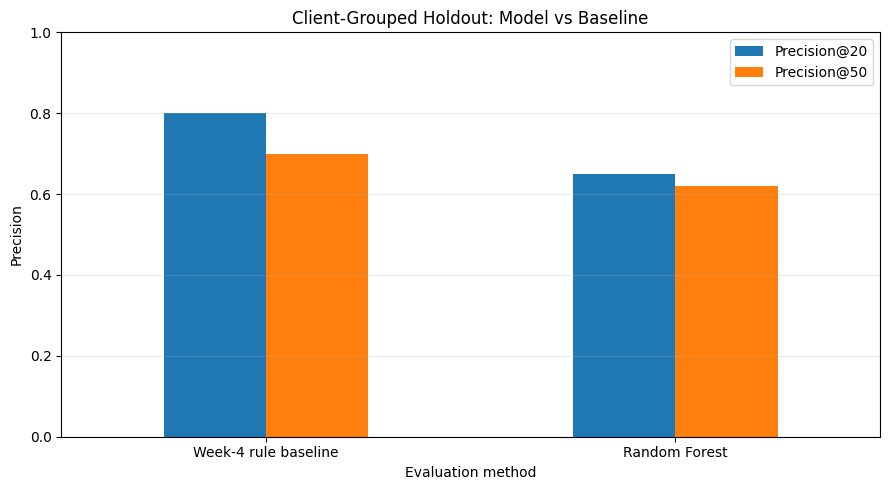

ARTIFACTS GENERATED
----------------------------------------
Chart: /content/Kifayat-Sayed/flyrank-ml-internship1/work/artifacts/grouped_precision_at_k.png
Metrics: /content/Kifayat-Sayed/flyrank-ml-internship1/work/artifacts/capstone_metrics.json
Client overlap: 0


In [29]:
# Create artifact directory inside the repository

ARTIFACT_DIR = REPO_DIR / "work" / "artifacts"

ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# 1. Grouped holdout comparison chart

primary_chart_data = (
    comparison[
        comparison["Split"] == "Client-grouped primary"
    ]
    .set_index("Method")[
        ["Precision@20", "Precision@50"]
    ]
)

fig, ax = plt.subplots(figsize=(9, 5))

primary_chart_data.plot(
    kind="bar",
    ax=ax,
    ylim=(0, 1),
    rot=0
)

ax.set_title(
    "Client-Grouped Holdout: Model vs Baseline"
)

ax.set_ylabel("Precision")
ax.set_xlabel("Evaluation method")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

chart_path = (
    ARTIFACT_DIR / "grouped_precision_at_k.png"
)

fig.savefig(
    chart_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# 2. Aggregate metrics for the research paper

metrics_summary = {
    "research_question": (
        "Can content and search-performance signals "
        "prioritize review items for unseen clients?"
    ),

    "dataset_rows": int(len(data)),

    "dataset_columns_including_target": int(data.shape[1]),

    "unique_clients": int(data["client_id"].nunique()),

    "decline_label_prevalence": float(y.mean()),

    "feature_count": int(len(feature_cols)),

    "grouped_train_rows": int(len(group_train_idx)),

    "grouped_test_rows": int(len(group_test_idx)),

    "grouped_train_clients": int(len(train_clients)),

    "grouped_test_clients": int(len(test_clients)),

    "client_overlap": int(
        len(train_clients & test_clients)
    ),

    "evaluation_results": comparison.to_dict(
        orient="records"
    ),

    "interpretation": (
        "Decision-support ranking only. "
        "No prospective prediction or causal refresh effect "
        "is established."
    )
}

metrics_path = (
    ARTIFACT_DIR / "capstone_metrics.json"
)

with open(
    metrics_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metrics_summary,
        f,
        indent=4
    )


print("ARTIFACTS GENERATED")
print("-" * 40)
print("Chart:", chart_path)
print("Metrics:", metrics_path)
print("Client overlap:", len(train_clients & test_clients))

assert len(train_clients & test_clients) == 0

## 8. ML-12: Communication and Submission

### Five-minute project demonstration

1. **Problem (0:00–0:40):** Explain why editorial teams need to prioritize content reviews.
2. **Dataset (0:40–1:30):** Introduce the anonymized dataset, target definition, and leakage exclusions.
3. **Method (1:30–2:30):** Explain the Random Forest pipeline, baseline, and client-grouped validation.
4. **Results (2:30–3:40):** Compare Precision@20 and Precision@50. Explain honestly whether the model outperformed the baseline.
5. **Recommendations (3:40–4:30):** Demonstrate the ranked review queue and its reason codes.
6. **Limitations (4:30–5:00):** Explain why the system supports human review rather than automatic refresh decisions.

### Social media summary

Developed a human-in-the-loop content refresh opportunity scoring workflow using an anonymized search-content dataset. Compared a Random Forest model with a simple recency-and-impressions baseline and evaluated generalization using a client-grouped holdout. The project demonstrates the importance of leakage prevention, honest validation, and explainable editorial decision support.

### Employer-facing summary

Built an end-to-end content review prioritization workflow using Python, pandas, and scikit-learn. Implemented preprocessing and leakage controls, compared a Random Forest against a business-rule baseline, and evaluated ranking performance on unseen clients. Generated a ranked review queue and documented the limitations of using historical search-performance data for editorial decisions.

### Final submission checklist

- [ ] All notebook cells execute successfully from top to bottom.
- [ ] Client overlap in the primary evaluation is zero.
- [ ] Results in the research paper match the executed notebook.
- [ ] No private client names, URLs, queries, credentials, or row-level records appear in public artifacts.
- [ ] Research paper is publicly deployed and includes all required sections.
- [ ] Research paper contains the required FlyRank data credit.
- [ ] `submission/paper_url.txt` contains exactly one line with the deployed paper URL.
- [ ] Completed notebook and artifacts are committed to the correct repository.
- [ ] Repository URL is submitted on the Week 8 capstone card.